# EngageIQ — Engagement Intelligence Engine

**EngageIQ** uses the trained **Model A** (trending) and **Model B** (audience) from Conjugate Media to score any post and suggest how to improve engagement.

### What you get
| Output | Meaning |
|--------|---------|
| **Model A score** | Trending potential from title / caption / tags (0–100) |
| **Model B score** | Expected engagement for your audience type (0–100) |
| **Final EngageIQ score** | Weighted blend of A + B |
| **Suggestions** | Concrete tips to raise engagement |

### Models loaded from
`conjugate-media/server/ml_models/`
- `model_A_trending_gb.joblib`
- `model_A_trending_clf.joblib`
- `model_B_audience_engagement.joblib`
- `model_B_audience_rf.joblib`
- `model_B_audience_clusters.joblib`


## 1. Setup — imports & model paths

In [1]:
import warnings
warnings.filterwarnings('ignore')

import re
import math
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib

MODEL_DIR = Path('C:/Users/saura/OneDrive/Desktop/projects/sem7/EngageIQfinal/EngageIQ/conjugate-media/server/ml_models')
assert MODEL_DIR.exists(), f'Model folder not found: {MODEL_DIR.resolve()}'

print('Models available:')
for p in sorted(MODEL_DIR.glob('*.joblib')):
    print(f'  {p.name:40s}  {p.stat().st_size/1024:8.1f} KB')


Models available:
  model_A_trending_clf.joblib                  378.0 KB
  model_A_trending_gb.joblib                   229.6 KB
  model_B_audience_clusters.joblib               7.4 KB
  model_B_audience_engagement.joblib         10378.9 KB
  model_B_audience_rf.joblib                 10384.8 KB


## 2. Load trained models

In [2]:
pipe_A_reg  = joblib.load(MODEL_DIR / 'model_A_trending_gb.joblib')       # engagement_score regressor
pipe_A_clf  = joblib.load(MODEL_DIR / 'model_A_trending_clf.joblib')      # high vs low classifier
pipe_B_aud  = joblib.load(MODEL_DIR / 'model_B_audience_engagement.joblib')  # audience-aware engagement
pipe_B_rf   = joblib.load(MODEL_DIR / 'model_B_audience_rf.joblib')       # meta-only engagement (fallback)
cluster_bundle = joblib.load(MODEL_DIR / 'model_B_audience_clusters.joblib')

HIGH_THR_A = float(cluster_bundle.get('high_threshold_A', 34.0))
CLUSTER_NAMES = cluster_bundle.get('cluster_names', {})

print('Model A regressor :', type(pipe_A_reg.named_steps['model']).__name__)
print('Model A classifier:', type(pipe_A_clf.named_steps['model']).__name__)
print('Model B audience  :', type(pipe_B_aud.named_steps['model']).__name__)
print('High-engagement threshold (A):', round(HIGH_THR_A, 2))
print('Audience cluster map:', CLUSTER_NAMES)


Model A regressor : GradientBoostingRegressor
Model A classifier: RandomForestClassifier
Model B audience  : RandomForestRegressor
High-engagement threshold (A): 34.43
Audience cluster map: {0: 'Steady / Broad Reach', 1: 'Steady / Broad Reach', 2: 'Loyal High-Reaction', 3: 'Viral Breakout'}


## 3. Helpers — text clean, feature builder

EngageIQ accepts a **post text** plus optional settings (platform, content type, duration, audience type, …).  
Missing values use sensible defaults so you can score with text alone.


In [3]:
def clean_text(s):
    if s is None or (isinstance(s, float) and math.isnan(s)):
        return ''
    s = str(s).lower()
    s = re.sub(r'http\S+|www\S+', ' ', s)
    s = re.sub(r'[^a-z0-9\s#@]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

# Default subscriber counts (from Conjugate channel profiles used in training)
DEFAULT_SUBS = {
    'youtube': 8_630_000,
    'instagram': 3_662_163,
    'facebook': 1_250_000,
    'linkedin': 485_000,
    'twitter': 650_000,
}

# Typical view/like priors by platform (used only to fill breakout/virality when user has no metrics yet)
PLATFORM_PRIORS = {
    'youtube':   {'views': 500_000, 'likes': 20_000, 'comments': 800, 'shares': 200},
    'instagram': {'views': 200_000, 'likes': 15_000, 'comments': 300, 'shares': 100},
    'facebook':  {'views': 150_000, 'likes': 8_000,  'comments': 200, 'shares': 150},
    'linkedin':  {'views': 25_000,  'likes': 400,    'comments': 40,  'shares': 20},
    'twitter':   {'views': 30_000,  'likes': 500,    'comments': 50,  'shares': 80},
}

CONTENT_TYPES = ['video', 'image', 'text', 'reel', 'short', 'carousel']
PLATFORMS = ['youtube', 'instagram', 'facebook', 'linkedin', 'twitter']
AUDIENCE_TYPES = [
    'Viral Breakout',
    'Loyal High-Reaction',
    'Short-Form / Reel Audience',
    'Steady / Broad Reach',
]

def infer_content_type_from_text(text, duration_sec=None, explicit=None):
    if explicit:
        return explicit
    t = (text or '').lower()
    if duration_sec is not None and duration_sec > 0:
        if duration_sec <= 60:
            return 'reel'
        return 'video'
    if any(w in t for w in ['#reel', 'reel', 'shorts', '#shorts']):
        return 'reel'
    if any(w in t for w in ['photo', 'image', 'pic', 'carousel']):
        return 'image'
    return 'text'

def build_features(
    text,
    platform='youtube',
    content_type=None,
    audience_type='Steady / Broad Reach',
    duration_sec=None,
    tags='',
    post_hour=None,
    post_dayofweek=None,
    subscribers=None,
    views=None,
    likes=None,
    comments=None,
    shares=None,
):
    """Build feature dicts for Model A and Model B from a post."""
    platform = (platform or 'youtube').lower().strip()
    if platform not in PLATFORMS:
        platform = 'youtube'

    text_clean = clean_text(text)
    tags_clean = clean_text(tags)
    combined = (text_clean + ' ' + tags_clean).strip()

    # Duration defaults
    if duration_sec is None or (isinstance(duration_sec, float) and math.isnan(duration_sec)):
        duration_sec = 0.0
    duration_sec = float(duration_sec)

    ctype = infer_content_type_from_text(text, duration_sec, content_type)
    if ctype not in CONTENT_TYPES:
        ctype = 'text'

    is_vertical_reel = 1 if ctype in ('reel', 'short') or platform == 'instagram' and ctype == 'video' else 0
    is_short_form = 1 if ctype in ('reel', 'short') or (duration_sec > 0 and duration_sec <= 60) else 0

    now = datetime.now(timezone.utc)
    if post_hour is None:
        post_hour = now.hour
    if post_dayofweek is None:
        post_dayofweek = now.weekday()
    is_weekend = 1 if post_dayofweek >= 5 else 0

    tags_count = len([t for t in re.split(r'[\s,|#]+', tags_clean) if t]) if tags_clean else 0
    # also count hashtags inside main text
    tags_count += len(re.findall(r'#\w+', text or ''))
    text_len = len(combined)

    # Metrics for breakout / virality (priors if unknown)
    prior = PLATFORM_PRIORS.get(platform, PLATFORM_PRIORS['youtube'])
    views = float(views) if views is not None else float(prior['views'])
    likes = float(likes) if likes is not None else float(prior['likes'])
    comments = float(comments) if comments is not None else float(prior['comments'])
    shares = float(shares) if shares is not None else float(prior['shares'])
    subs = float(subscribers) if subscribers is not None else float(DEFAULT_SUBS.get(platform, 100_000))

    breakout = math.log((views + 1) / (subs + 1))
    virality = views + 15 * likes + 50 * comments + 100 * shares
    log_virality = math.log1p(virality)

    if audience_type not in AUDIENCE_TYPES:
        audience_type = 'Steady / Broad Reach'

    # Model A row (needs column name 'text')
    row_A = {
        'platform': platform,
        'content_type': ctype,
        'duration_sec': duration_sec,
        'tags_count': tags_count,
        'text_len': text_len,
        'post_hour': int(post_hour),
        'post_dayofweek': int(post_dayofweek),
        'is_weekend': is_weekend,
        'is_vertical_reel': is_vertical_reel,
        'is_short_form': is_short_form,
        'text': combined,
    }

    # Model B audience-aware row
    row_B = {
        'platform': platform,
        'content_type': ctype,
        'audience_type': audience_type,
        'duration_sec': duration_sec,
        'text_len': text_len,
        'tags_count': tags_count,
        'post_hour': int(post_hour),
        'post_dayofweek': int(post_dayofweek),
        'is_weekend': is_weekend,
        'is_vertical_reel': is_vertical_reel,
        'is_short_form': is_short_form,
        'subscribers': subs,
        'breakout_log_ratio': breakout,
        'log_virality': log_virality,
    }

    # Model B meta-only (no audience_type)
    row_B_meta = {k: v for k, v in row_B.items() if k != 'audience_type'}

    meta = {
        'platform': platform,
        'content_type': ctype,
        'audience_type': audience_type,
        'duration_sec': duration_sec,
        'is_short_form': is_short_form,
        'is_vertical_reel': is_vertical_reel,
        'text_len': text_len,
        'tags_count': tags_count,
        'post_hour': int(post_hour),
        'post_dayofweek': int(post_dayofweek),
        'subscribers': subs,
        'views_used': views,
        'likes_used': likes,
    }
    return row_A, row_B, row_B_meta, meta

print('Feature builder ready')


Feature builder ready


## 4. EngageIQ scorer

Final score formula (default weights):

\\[
\text{Final} = 0.45 \times \text{Model A} + 0.55 \times \text{Model B (audience-aware)}
\\]

You can change the weights below.


In [4]:
# Weights for final blend (must sum to 1.0 ideally)
WEIGHT_A = 0.45   # trending potential
WEIGHT_B = 0.55   # audience fit / expected engagement

def score_label(score, high_thr=HIGH_THR_A):
    if score >= 60:
        return 'Excellent'
    if score >= high_thr:
        return 'Good / High potential'
    if score >= 25:
        return 'Average'
    return 'Low — needs work'


def engageiq_score(
    text,
    platform='youtube',
    content_type=None,
    audience_type='Steady / Broad Reach',
    duration_sec=None,
    tags='',
    post_hour=None,
    post_dayofweek=None,
    subscribers=None,
    views=None,
    likes=None,
    comments=None,
    shares=None,
    weight_a=WEIGHT_A,
    weight_b=WEIGHT_B,
    verbose=True,
):
    """
    Score a post with Model A + Model B and return a full result dict.
    """
    if not text or not str(text).strip():
        raise ValueError('Please provide post text / caption / title.')

    row_A, row_B, row_B_meta, meta = build_features(
        text=text,
        platform=platform,
        content_type=content_type,
        audience_type=audience_type,
        duration_sec=duration_sec,
        tags=tags,
        post_hour=post_hour,
        post_dayofweek=post_dayofweek,
        subscribers=subscribers,
        views=views,
        likes=likes,
        comments=comments,
        shares=shares,
    )

    df_A = pd.DataFrame([row_A])
    df_B = pd.DataFrame([row_B])
    df_Bm = pd.DataFrame([row_B_meta])

    # --- Model A ---
    score_A = float(pipe_A_reg.predict(df_A)[0])
    try:
        proba_high = float(pipe_A_clf.predict_proba(df_A)[0][1])
        label_A = 'HIGH trending' if pipe_A_clf.predict(df_A)[0] == 1 else 'low/mid trending'
    except Exception:
        proba_high = None
        label_A = 'HIGH trending' if score_A >= HIGH_THR_A else 'low/mid trending'

    # --- Model B ---
    score_B_aud = float(pipe_B_aud.predict(df_B)[0])
    score_B_meta = float(pipe_B_rf.predict(df_Bm)[0])
    # Prefer audience-aware; keep meta as secondary signal
    score_B = 0.7 * score_B_aud + 0.3 * score_B_meta

    # Clip to 0–100
    score_A = float(np.clip(score_A, 0, 100))
    score_B = float(np.clip(score_B, 0, 100))
    score_B_aud = float(np.clip(score_B_aud, 0, 100))

    final = float(np.clip(weight_a * score_A + weight_b * score_B, 0, 100))

    result = {
        'text_preview': str(text)[:120] + ('…' if len(str(text)) > 120 else ''),
        'platform': meta['platform'],
        'content_type': meta['content_type'],
        'audience_type': meta['audience_type'],
        'model_A_score': round(score_A, 2),
        'model_A_label': label_A,
        'model_A_high_proba': None if proba_high is None else round(proba_high, 3),
        'model_B_score': round(score_B, 2),
        'model_B_audience_score': round(score_B_aud, 2),
        'model_B_meta_score': round(float(np.clip(score_B_meta, 0, 100)), 2),
        'final_engageiq_score': round(final, 2),
        'final_label': score_label(final),
        'meta': meta,
    }

    if verbose:
        print('=' * 56)
        print('EngageIQ Scorecard')
        print('=' * 56)
        print(f"Post     : {result['text_preview']}")
        print(f"Platform : {result['platform']}  |  Type: {result['content_type']}  |  Audience: {result['audience_type']}")
        print('-' * 56)
        print(f"Model A (Trending)     : {result['model_A_score']:6.1f}   [{result['model_A_label']}]"
              + (f"  P(high)={result['model_A_high_proba']}" if result['model_A_high_proba'] is not None else ''))
        print(f"Model B (Audience)     : {result['model_B_score']:6.1f}   (audience-aware {result['model_B_audience_score']}, meta {result['model_B_meta_score']})")
        print(f"FINAL EngageIQ score   : {result['final_engageiq_score']:6.1f}   →  {result['final_label']}")
        print('=' * 56)

    return result

print('EngageIQ scorer ready')


EngageIQ scorer ready


## 5. Suggestion engine

Rules based on score gaps, content type, length, timing, and platform best practices.


In [5]:
def generate_suggestions(result, text):
    """Return a list of actionable suggestions to raise engagement."""
    tips = []
    score_A = result['model_A_score']
    score_B = result['model_B_score']
    final = result['final_engageiq_score']
    meta = result['meta']
    platform = meta['platform']
    ctype = meta['content_type']
    text_len = meta['text_len']
    tags_count = meta['tags_count']
    is_short = meta['is_short_form']
    hour = meta['post_hour']
    audience = result['audience_type']

    # --- Overall ---
    if final < 25:
        tips.append(('Critical', 'Overall engagement outlook is low. Rewrite the hook in the first line and add a clear call-to-action (question, save, share).'))
    elif final < HIGH_THR_A:
        tips.append(('Improve', 'Score is below the “high potential” band. Strengthen the title/hook and match format to what this audience rewards.'))
    else:
        tips.append(('Good', 'Solid baseline. Small format and timing tweaks can still push this into the top band.'))

    # --- Model A specific (text / trending) ---
    if score_A < 30:
        tips.append(('Trending (A)', 'Title/caption is weak for trending. Lead with a curiosity gap, number, or bold claim in the first 8–12 words.'))
    if text_len < 40:
        tips.append(('Trending (A)', 'Caption is very short. Add 1–2 lines of context or a story beat so the model (and viewers) have more signal.'))
    if text_len > 400 and platform in ('twitter', 'instagram'):
        tips.append(('Trending (A)', f'Caption is long for {platform}. Tighten to the key message; put detail in comments or a thread.'))
    if tags_count < 2 and platform in ('instagram', 'youtube', 'linkedin'):
        tips.append(('Trending (A)', 'Add 3–8 relevant tags/hashtags (mix of broad + niche) to improve discoverability.'))
    if tags_count > 15:
        tips.append(('Trending (A)', 'Too many tags can look spammy. Keep the strongest 5–10.'))

    # --- Model B specific (audience fit) ---
    if score_B < score_A - 10:
        tips.append(('Audience (B)', f'Content looks more “trending-shaped” than audience-fit for “{audience}”. Align format with what this audience usually engages with.'))
    if score_A < score_B - 10:
        tips.append(('Audience (B)', 'Audience model likes this more than the trending model. Keep the format; improve the hook/title for broader reach.'))

    if audience == 'Viral Breakout':
        tips.append(('Audience (B)', 'Viral-oriented audience: favour bold hooks, early visual payoff, and formats that get shares (reels/shorts, lists, strong opinion).'))
    elif audience == 'Loyal High-Reaction':
        tips.append(('Audience (B)', 'Loyal audience: ask a question, invite comments, use “you/your”, and post consistently in the same style.'))
    elif audience == 'Short-Form / Reel Audience':
        tips.append(('Audience (B)', 'Short-form audience: keep under ~60s, vertical, captions on-screen, pattern interrupt in the first 3 seconds.'))
    else:  # Steady
        tips.append(('Audience (B)', 'Steady audience: reliable value (how-to, insight, series). Avoid pure clickbait; clarity beats hype.'))

    # --- Format / platform ---
    if platform == 'youtube' and ctype == 'text':
        tips.append(('Format', 'YouTube rewards video. If this is a video idea, set content_type="video" and a realistic duration_sec.'))
    if platform == 'instagram' and ctype == 'text' and not is_short:
        tips.append(('Format', 'On Instagram, reels and carousels usually outperform plain text. Consider content_type="reel" with duration ≤ 60s.'))
    if platform == 'linkedin' and ctype in ('reel', 'short'):
        tips.append(('Format', 'LinkedIn still skews to text/document carousels for many B2B audiences. Test a text version with a strong first line.'))
    if platform == 'twitter' and text_len > 240:
        tips.append(('Format', 'For X/Twitter, consider a short lead tweet + thread instead of one long block.'))

    if is_short == 0 and platform in ('instagram', 'youtube') and (meta['duration_sec'] or 0) > 180:
        tips.append(('Format', 'Long-form can work, but also ship a 30–60s cutdown for short-form surfaces (Shorts/Reels).'))

    # --- Timing ---
    if hour is not None and (hour < 7 or hour > 22):
        tips.append(('Timing', f'Post hour={hour} UTC is off-peak for many regions. Try late morning or early evening in your audience timezone.'))
    if meta.get('post_dayofweek') is not None and meta['post_dayofweek'] >= 5 and platform == 'linkedin':
        tips.append(('Timing', 'LinkedIn engagement often dips on weekends. Schedule for Tue–Thu if targeting professionals.'))

    # --- CTA ---
    lower = (text or '').lower()
    cta_words = ['comment', 'share', 'save', 'subscribe', 'follow', 'what do you think', 'agree', 'tag']
    if not any(w in lower for w in cta_words):
        tips.append(('CTA', 'No clear call-to-action detected. End with a question or ask viewers to comment/save/share.'))

    # Deduplicate while preserving order
    seen = set()
    unique = []
    for level, msg in tips:
        key = (level, msg)
        if key not in seen:
            seen.add(key)
            unique.append((level, msg))
    return unique


def print_suggestions(tips):
    print('\nSuggestions to increase engagement')
    print('-' * 56)
    icon = {'Critical': '!!', 'Improve': '*', 'Good': '+', 'Trending (A)': 'A',
            'Audience (B)': 'B', 'Format': 'F', 'Timing': 'T', 'CTA': 'C'}
    for level, msg in tips:
        tag = icon.get(level, '•')
        print(f'[{tag}] {level:14s}  {msg}')
    print('-' * 56)


def engageiq_analyze(text, **kwargs):
    """Full pipeline: score + suggestions."""
    result = engageiq_score(text, verbose=True, **kwargs)
    tips = generate_suggestions(result, text)
    print_suggestions(tips)
    result['suggestions'] = [{'level': lv, 'message': msg} for lv, msg in tips]
    return result

print('Suggestion engine ready')


Suggestion engine ready


## 6. Try EngageIQ — examples

Edit the text and options, then re-run the cell.


In [6]:
# ---------- EXAMPLE 1: YouTube video idea ----------
result1 = engageiq_analyze(
    text='Official Trailer | Superstar Action Movie 2026 — mind-blowing stunts you have never seen',
    platform='youtube',
    content_type='video',
    duration_sec=150,
    tags='trailer action movie 2026',
    audience_type='Viral Breakout',
    post_hour=18,
    post_dayofweek=4,  # Friday
)


EngageIQ Scorecard
Post     : Official Trailer | Superstar Action Movie 2026 — mind-blowing stunts you have never seen
Platform : youtube  |  Type: video  |  Audience: Viral Breakout
--------------------------------------------------------
Model A (Trending)     :   36.9   [HIGH trending]  P(high)=0.719
Model B (Audience)     :   69.0   (audience-aware 69.96, meta 66.77)
FINAL EngageIQ score   :   54.5   →  Good / High potential

Suggestions to increase engagement
--------------------------------------------------------
[+] Good            Solid baseline. Small format and timing tweaks can still push this into the top band.
[B] Audience (B)    Audience model likes this more than the trending model. Keep the format; improve the hook/title for broader reach.
[B] Audience (B)    Viral-oriented audience: favour bold hooks, early visual payoff, and formats that get shares (reels/shorts, lists, strong opinion).
[C] CTA             No clear call-to-action detected. End with a question or ask 

In [7]:
# ---------- EXAMPLE 2: LinkedIn text post ----------
result2 = engageiq_analyze(
    text='We are hiring a Motion Graphics Designer. Remote friendly. Portfolio in comments.',
    platform='linkedin',
    content_type='text',
    duration_sec=0,
    tags='',
    audience_type='Steady / Broad Reach',
    post_hour=10,
    post_dayofweek=2,  # Wednesday
)


EngageIQ Scorecard
Post     : We are hiring a Motion Graphics Designer. Remote friendly. Portfolio in comments.
Platform : linkedin  |  Type: text  |  Audience: Steady / Broad Reach
--------------------------------------------------------
Model A (Trending)     :   32.8   [low/mid trending]  P(high)=0.35
Model B (Audience)     :   34.8   (audience-aware 34.94, meta 34.46)
FINAL EngageIQ score   :   33.9   →  Average

Suggestions to increase engagement
--------------------------------------------------------
[*] Improve         Score is below the “high potential” band. Strengthen the title/hook and match format to what this audience rewards.
[A] Trending (A)    Add 3–8 relevant tags/hashtags (mix of broad + niche) to improve discoverability.
[B] Audience (B)    Steady audience: reliable value (how-to, insight, series). Avoid pure clickbait; clarity beats hype.
--------------------------------------------------------


In [8]:
# ---------- EXAMPLE 3: Instagram reel ----------
result3 = engageiq_analyze(
    text='3 morning habits that 10x my focus  #productivity #reels',
    platform='instagram',
    content_type='reel',
    duration_sec=35,
    tags='productivity habits morning',
    audience_type='Short-Form / Reel Audience',
    post_hour=9,
    post_dayofweek=1,
)


EngageIQ Scorecard
Post     : 3 morning habits that 10x my focus  #productivity #reels
Platform : instagram  |  Type: reel  |  Audience: Short-Form / Reel Audience
--------------------------------------------------------
Model A (Trending)     :   37.9   [low/mid trending]  P(high)=0.361
Model B (Audience)     :   59.5   (audience-aware 59.15, meta 60.48)
FINAL EngageIQ score   :   49.8   →  Good / High potential

Suggestions to increase engagement
--------------------------------------------------------
[+] Good            Solid baseline. Small format and timing tweaks can still push this into the top band.
[B] Audience (B)    Audience model likes this more than the trending model. Keep the format; improve the hook/title for broader reach.
[B] Audience (B)    Short-form audience: keep under ~60s, vertical, captions on-screen, pattern interrupt in the first 3 seconds.
[C] CTA             No clear call-to-action detected. End with a question or ask viewers to comment/save/share.
-------

## 7. Your turn — score any post

Change the variables in the next cell and run it.


In [9]:
# ===================== USER INPUT =====================
MY_TEXT = """
Your post title or caption goes here.
Ask a question or add a CTA at the end.
"""

MY_PLATFORM = 'youtube'          # youtube | instagram | facebook | linkedin | twitter
MY_CONTENT_TYPE = 'video'        # video | image | text | reel | short | carousel
MY_AUDIENCE_TYPE = 'Steady / Broad Reach'
# options: Viral Breakout | Loyal High-Reaction | Short-Form / Reel Audience | Steady / Broad Reach
MY_DURATION_SEC = 180            # 0 for text posts
MY_TAGS = 'tag1 tag2'            # optional
MY_HOUR = 12                     # 0–23 UTC
MY_DOW = 2                       # 0=Mon … 6=Sun
# Optional real metrics (leave None to use platform priors)
MY_VIEWS = None
MY_LIKES = None
MY_SUBS = None
# ======================================================

my_result = engageiq_analyze(
    text=MY_TEXT,
    platform=MY_PLATFORM,
    content_type=MY_CONTENT_TYPE,
    audience_type=MY_AUDIENCE_TYPE,
    duration_sec=MY_DURATION_SEC,
    tags=MY_TAGS,
    post_hour=MY_HOUR,
    post_dayofweek=MY_DOW,
    views=MY_VIEWS,
    likes=MY_LIKES,
    subscribers=MY_SUBS,
)


EngageIQ Scorecard
Post     : 
Your post title or caption goes here.
Ask a question or add a CTA at the end.

Platform : youtube  |  Type: video  |  Audience: Steady / Broad Reach
--------------------------------------------------------
Model A (Trending)     :   45.8   [HIGH trending]  P(high)=0.595
Model B (Audience)     :   65.2   (audience-aware 64.62, meta 66.42)
FINAL EngageIQ score   :   56.5   →  Good / High potential

Suggestions to increase engagement
--------------------------------------------------------
[+] Good            Solid baseline. Small format and timing tweaks can still push this into the top band.
[B] Audience (B)    Audience model likes this more than the trending model. Keep the format; improve the hook/title for broader reach.
[B] Audience (B)    Steady audience: reliable value (how-to, insight, series). Avoid pure clickbait; clarity beats hype.
[C] CTA             No clear call-to-action detected. End with a question or ask viewers to comment/save/share.
---

## 8. Visual comparison of scores


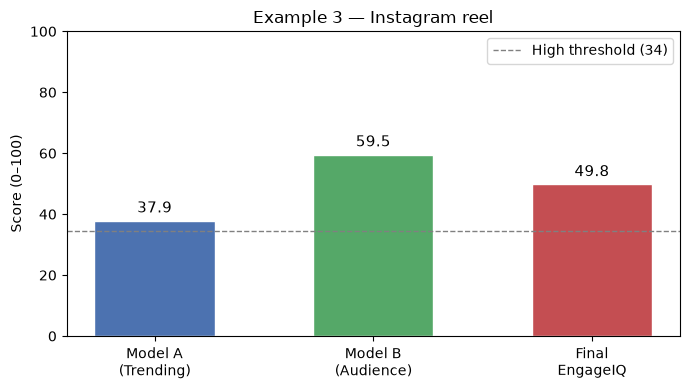

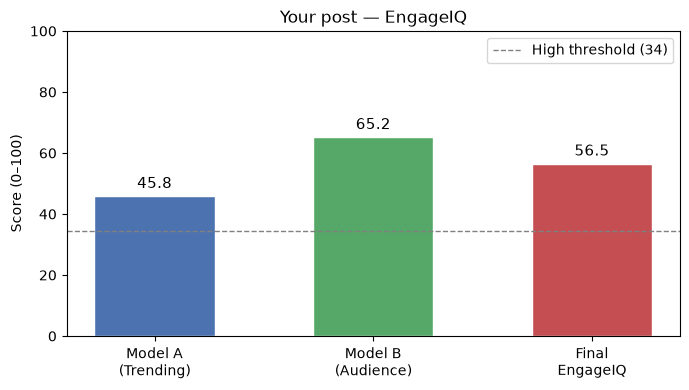

In [10]:
def plot_scorecard(result, title='EngageIQ scorecard'):
    labels = ['Model A\n(Trending)', 'Model B\n(Audience)', 'Final\nEngageIQ']
    values = [
        result['model_A_score'],
        result['model_B_score'],
        result['final_engageiq_score'],
    ]
    colors = ['#4C72B0', '#55A868', '#C44E52']
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(labels, values, color=colors, edgecolor='white', width=0.55)
    ax.set_ylim(0, 100)
    ax.axhline(HIGH_THR_A, color='gray', ls='--', lw=1, label=f'High threshold ({HIGH_THR_A:.0f})')
    ax.set_ylabel('Score (0–100)')
    ax.set_title(title)
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width()/2, v + 1.5, f'{v:.1f}', ha='center', va='bottom', fontsize=11)
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

# Plot last example that was run (example 3) and user cell if available
plot_scorecard(result3, title='Example 3 — Instagram reel')
if 'my_result' in dir() or 'my_result' in globals():
    try:
        plot_scorecard(my_result, title='Your post — EngageIQ')
    except Exception:
        pass


## 9. Batch mode — score many posts from a list


In [11]:
posts = [
    {'text': 'How I grew to 1M subscribers with one content system', 'platform': 'youtube', 'content_type': 'video', 'duration_sec': 720, 'audience_type': 'Steady / Broad Reach'},
    {'text': 'Unpopular opinion: most productivity apps waste your time. Agree?', 'platform': 'twitter', 'content_type': 'text', 'duration_sec': 0, 'audience_type': 'Loyal High-Reaction'},
    {'text': 'Behind the scenes of our documentary edit  #filmmaking #reels', 'platform': 'instagram', 'content_type': 'reel', 'duration_sec': 28, 'audience_type': 'Short-Form / Reel Audience'},
    {'text': 'Three lessons from shipping AI features to 50k users this quarter.', 'platform': 'linkedin', 'content_type': 'text', 'duration_sec': 0, 'audience_type': 'Steady / Broad Reach'},
]

rows = []
for p in posts:
    r = engageiq_score(verbose=False, **p)
    rows.append({
        'preview': r['text_preview'][:50],
        'platform': r['platform'],
        'type': r['content_type'],
        'A': r['model_A_score'],
        'B': r['model_B_score'],
        'Final': r['final_engageiq_score'],
        'label': r['final_label'],
    })

batch_df = pd.DataFrame(rows)
print(batch_df.to_string(index=False))


                                           preview  platform  type     A     B  Final                 label
How I grew to 1M subscribers with one content syst   youtube video 37.13 65.55  52.76 Good / High potential
Unpopular opinion: most productivity apps waste yo   twitter  text  7.39 23.56  16.28      Low — needs work
Behind the scenes of our documentary edit  #filmma instagram  reel 36.72 59.74  49.38 Good / High potential
Three lessons from shipping AI features to 50k use  linkedin  text 26.83 34.91  31.28               Average


## 10. How EngageIQ fits with Conjugate Media

```text
Raw JSON scrapes
    → build_ml_ready_datasets.ipynb   →  ml_ready/*.csv
    → conjugate-media-model-A-B-training.ipynb  →  ml_models/*.joblib
    → EngageIQ.ipynb  (this file)  →  scores + suggestions for a new post
```

| Piece | Role |
|-------|------|
| Model A | “Will this trend?” from text + format |
| Model B | “How will *my* audience respond?” |
| EngageIQ final | Blended decision score + tips |

Re-train models anytime with the training notebook; EngageIQ will pick up new `.joblib` files on reload (re-run section 2).


In [12]:
print('EngageIQ is ready.')
print('Models dir:', MODEL_DIR.resolve())
print('Try section 7 with your own caption.')


EngageIQ is ready.
Models dir: C:\Users\saura\OneDrive\Desktop\projects\sem7\EngageIQfinal\EngageIQ\conjugate-media\server\ml_models
Try section 7 with your own caption.
